# What the Dice score `D` actually measures, from the basics

This notebook is a read-only post-mortem of one number in the PlasmaFlow rollout results table
(`tab:rollout_results_depth`): the mode-agreement **Dice score `D`**.

**The problem.** In the paper table, PlasmaFlow has the highest mean `D` of all five models. But a
paired statistical test across the 43 test shots says PlasmaFlow is *not* significantly better than
U-Net, iTransformer, or DLinear, and PlasmaFlow actually "wins" on fewer than half the shots despite
the higher average. A higher mean with a below-half win rate is a warning sign: it usually means the
average is being carried by a few large wins while the typical shot goes the other way, or that the
metric is saturated and cannot tell the models apart on most shots.

**The hypothesis we test.** Many of the evaluated windows may contain no confinement-mode transition
at all. If the ground truth just sits in one mode the whole time, then any model whose output gets
classified as that same constant mode scores `D` close to 1.0. Every model looks near-perfect, the
scores bunch up against the ceiling, and `D` carries almost no information about which model actually
reproduces mode *dynamics*.

**Nothing here is retrained or rerun.** Every number comes from result files that already exist on
disk. We only read them.

**What you need to know to follow along:**

- A *shot* is one real tokamak discharge. There are 43 in the test set.
- The model is asked to generate the future of a shot in chunks called *windows*, one after another,
  each window feeding into the next. This is the *rollout*. Window index `k` counts how many steps of
  self-generated input the model is standing on, so larger `k` is a harder, more drifted prediction.
- The table splits the first 12 windows into two halves: **early** (`k` = 0 to 5) and **late**
  (`k` = 6 to 11).
- At every timestep, a separate pretrained classifier assigns a *confinement mode* label:
  **L** (low confinement), **D** (dithering), or **H** (high confinement). It does this to both the
  real signal and the generated signal.
- `D` compares those two label sequences. That is all it does. It never looks at the raw signal.

## 0. Setup

PlasmaFlow is stochastic, so it produces 30 different samples per shot; the deterministic baselines
produce 1. Everything below averages the 30 samples down to one value per shot *before* comparing
models, which is what the paper table does.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, binomtest

# Find the repo root (the directory containing output/paper_tables) by walking up from cwd.
ROOT = Path.cwd()
while not (ROOT / "output" / "paper_tables").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
TABLES = ROOT / "output" / "paper_tables"
CACHE = ROOT / "output" / "test_cache"
print("repo root:", ROOT)

# Aggregation settings, copied from the paper table / _depth_table_se_analysis.py so this notebook
# reproduces the published cells exactly.
START_FRAC = 0.50                 # rollouts seeded halfway through the shot
HALVES = {"early": range(0, 6), "late": range(6, 12)}
TIE_TOL = 1e-6                    # two Dice values this close are called an exact tie
CHANNEL = "PD"                    # Dice is identical for every channel; pick one to avoid duplicates
THRESHOLD = "all_peaks"

# Rollout geometry, from the cached record attributes.
HIST = 256        # history samples fed in before generation starts
STEP = 256        # window stride
SPILL = 15        # label_spill: Dice window reaches 15 samples back, see rollout_slice_metrics.meta.json
SAMPLE_RATE = 10_000.0   # Hz, so one sample is 0.1 ms

MODELS = {
    "PlasmaFlow":   "R-CNb-cfm-noleak-normal-s05-noatt-e2_rollout",
    "U-Net":        "UNb-unet-noleak-noatt_rollout",
    "TiDE":         "R-TN-tide-noleak-e2_rollout",
    "iTransformer": "R-IN-itransformer-noleak-e2_rollout",
    "DLinear":      "D-dlinear-r2_rollout",
}
BASELINES = ["U-Net", "TiDE", "iTransformer", "DLinear"]
MODE_NAMES = {0: "L", 1: "D", 2: "H"}      # unshifted surrogate convention, see note below
MODE_COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#E45756"}

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200, "display.max_columns", 50)

repo root: /Users/milan/Code/fusion/experiments


## 1. What `D` is, precisely

The definition lives in `src/metrics/rollout_peaks.py`, function `dice_scores` (around line 73). Two
variants are computed per window:

- **micro Dice**, which is what the paper reports as `D`. For a sequence where every timestep carries
  exactly one label, micro Dice reduces to **plain accuracy**: the fraction of timesteps where the
  generated label equals the real label. The source code says so in its own docstring.
- **macro Dice**, the unweighted mean of the per-class Dice over the classes present. Because it
  weights the rare D and H modes as heavily as the common L mode, it is more sensitive to the rare
  modes. It is computed and cached but not reported in the table. We will look at it as a contrast.

The practical consequence of `D` being accuracy: **if the ground truth is 95 percent one mode, then
predicting that one mode constantly and never transitioning already scores 0.95.** Keep that in mind
for section 4.

A labelling gotcha worth stating, since this repo has two conventions in circulation: the labels
cached as `surr_labels_gen` / `surr_labels_real` are the **unshifted** surrogate-classifier outputs,
`0 = L`, `1 = D`, `2 = H`, with no "Unknown" class. That is the convention used throughout this
notebook.

We reimplement `dice_scores` verbatim below rather than importing it, so this notebook has no
dependency on the training stack. Section 3 validates the reimplementation against the cached
published values, which proves the two agree.

In [2]:
def dice_scores(pred, target, n_classes=3):
    # Verbatim reimplementation of src/metrics/rollout_peaks.py::dice_scores.
    # Returns (micro, macro). Micro Dice on a single-label sequence is just accuracy.
    pred = np.asarray(pred).astype(int)
    target = np.asarray(target).astype(int)
    micro = float((pred == target).mean()) if pred.size else float("nan")
    per_class = []
    for c in range(n_classes):
        p, t = pred == c, target == c
        denom = p.sum() + t.sum()
        if denom == 0:
            continue                      # class absent from both: undefined, not a free 1.0
        per_class.append(2.0 * float((p & t).sum()) / float(denom))
    macro = float(np.mean(per_class)) if per_class else float("nan")
    return micro, macro

# A quick sanity demo so the numbers below are not mysterious.
real = np.array([0]*90 + [2]*10)          # 90 percent L, then a short H phase
flat = np.zeros(100, dtype=int)           # a degenerate "always L" prediction
print("ground truth is 90% L, 10% H")
print("  'always L' prediction   -> micro D = %.3f, macro D = %.3f" % dice_scores(flat, real))
shifted = np.array([0]*95 + [2]*5)        # finds the H phase but 5 samples late
print("  H phase found 5 late    -> micro D = %.3f, macro D = %.3f" % dice_scores(shifted, real))

ground truth is 90% L, 10% H
  'always L' prediction   -> micro D = 0.900, macro D = 0.474
  H phase found 5 late    -> micro D = 0.950, macro D = 0.820


Note what the demo shows. The degenerate "always L" model, which never produces an H phase at all,
scores 0.900. A model that genuinely produces the H phase but mistimes its onset scores 0.950 on
micro Dice, only 0.05 better, while macro Dice separates them far more sharply (because the
degenerate model gets 0.0 on the H class). Micro Dice is a weak discriminator for exactly the
behaviour the paper cares about.

## 2. Load the published per-shot Dice values

`output/paper_tables/rollout_slice_metrics.parquet` holds one row per
(model, shot, rollout start, sample, window `k`, channel, peak threshold), with the `dice` and
`dice_macro` columns already computed. We rebuild the paper's aggregation ladder:

1. average over the windows inside a half, per sample,
2. average the 30 PlasmaFlow samples down to one number per shot,

which leaves exactly one value per (model, shot, half). 43 shots times 5 models times 2 halves.

In [3]:
sm = pd.read_parquet(TABLES / "rollout_slice_metrics.parquet")
print("raw parquet rows:", len(sm))

d = sm[np.isclose(sm["start_frac"], START_FRAC)
       & (sm["threshold_name"] == THRESHOLD)
       & (sm["channel"] == CHANNEL)].copy()
d["half"] = d["k"].apply(lambda k: "early" if k <= 5 else ("late" if k <= 11 else None))
d = d[d["half"].notna()]

# window -> sample mean, then sample -> shot mean
per_sample = d.groupby(["model", "shot", "half", "sample_idx"], as_index=False).agg(
    dice=("dice", "mean"), dice_macro=("dice_macro", "mean"))
per_shot = per_sample.groupby(["model", "shot", "half"], as_index=False).agg(
    dice=("dice", "mean"), dice_macro=("dice_macro", "mean"),
    n_samples=("sample_idx", "nunique"))

print("\nsamples per shot by model:")
print(per_shot.groupby("model")["n_samples"].agg(["min", "max"]))
print("\nshots per (model, half):", per_shot.groupby(["model", "half"]).size().unique())

print("\nMean D per model and half (these should match the paper table):")
print(per_shot.pivot_table(index="model", columns="half", values="dice").loc[list(MODELS)].round(3))

raw parquet rows: 2099160



samples per shot by model:
              min  max
model                 
DLinear         1    1
PlasmaFlow     30   30
TiDE            1    1
U-Net           1    1
iTransformer    1    1

shots per (model, half): [43]

Mean D per model and half (these should match the paper table):
half          early   late
model                     
PlasmaFlow    0.799  0.735
U-Net         0.750  0.643
TiDE          0.537  0.380
iTransformer  0.671  0.507
DLinear       0.778  0.533


## 3. Per-shot Dice distribution: one dot per shot

This is the first thing to look at and it already tells most of the story. Each dot is one shot. The
paper reports only the mean of each column of dots.

What to look for: whether the dots are spread smoothly (in which case the mean is meaningful and
differences between models are real) or **piled up against the 1.0 ceiling** (in which case most
shots are "too easy", every model aces them, and the mean is decided by a minority of hard shots).

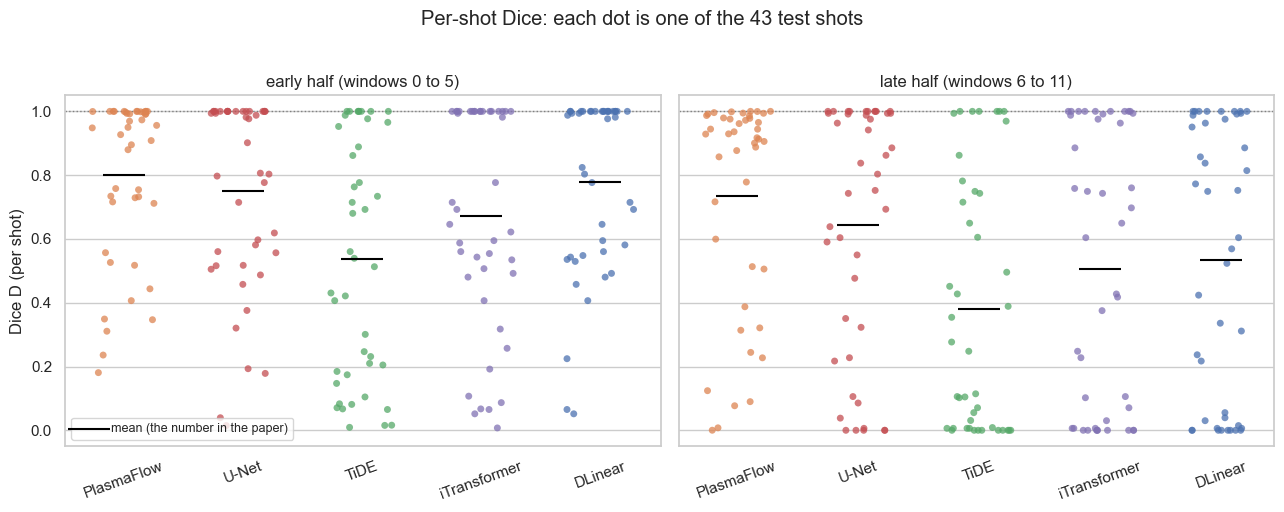

Fraction of shots scoring D > 0.99 (effectively a perfect score):
half          early   late
model                     
PlasmaFlow    0.395  0.186
U-Net         0.419  0.326
TiDE          0.186  0.163
iTransformer  0.419  0.256
DLinear       0.465  0.233

Fraction of shots scoring D > 0.95:
half          early   late
model                     
PlasmaFlow    0.465  0.372
U-Net         0.488  0.395
TiDE          0.279  0.186
iTransformer  0.442  0.326
DLinear       0.535  0.326


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, half in zip(axes, ["early", "late"]):
    sub = per_shot[per_shot.half == half]
    sns.stripplot(data=sub, x="model", y="dice", order=list(MODELS), ax=ax,
                  jitter=0.28, size=5, alpha=0.75, hue="model", palette="deep", legend=False)
    means = sub.groupby("model")["dice"].mean().loc[list(MODELS)]
    ax.scatter(range(len(means)), means.values, marker="_", s=900, color="black", zorder=5,
               label="mean (the number in the paper)")
    ax.axhline(1.0, ls=":", color="grey", lw=1)
    ax.set_title(f"{half} half (windows {min(HALVES[half])} to {max(HALVES[half])})")
    ax.set_xlabel(""); ax.set_ylabel("Dice D (per shot)")
    ax.tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle("Per-shot Dice: each dot is one of the 43 test shots", y=1.02)
plt.tight_layout(); plt.show()

print("Fraction of shots scoring D > 0.99 (effectively a perfect score):")
tbl = (per_shot.assign(near_perfect=per_shot.dice > 0.99)
       .pivot_table(index="model", columns="half", values="near_perfect", aggfunc="mean"))
print(tbl.loc[list(MODELS)].round(3))
print("\nFraction of shots scoring D > 0.95:")
tbl2 = (per_shot.assign(hi=per_shot.dice > 0.95)
        .pivot_table(index="model", columns="half", values="hi", aggfunc="mean"))
print(tbl2.loc[list(MODELS)].round(3))

## 4. Paired scatter: PlasmaFlow against each baseline, shot by shot

The mean hides *which* shots a model wins. Because every model is evaluated on the same 43 shots, we
can compare them shot by shot, which is a far more sensitive comparison than comparing two averages.

Each dot is one shot: PlasmaFlow's Dice on the vertical axis, the baseline's on the horizontal. The
diagonal is "the two models tied". Dots **above** the line are PlasmaFlow wins, **below** are losses,
and dots sitting exactly **on** the line at the top right corner are the easy shots where both models
scored the same near-perfect value and the metric learned nothing.

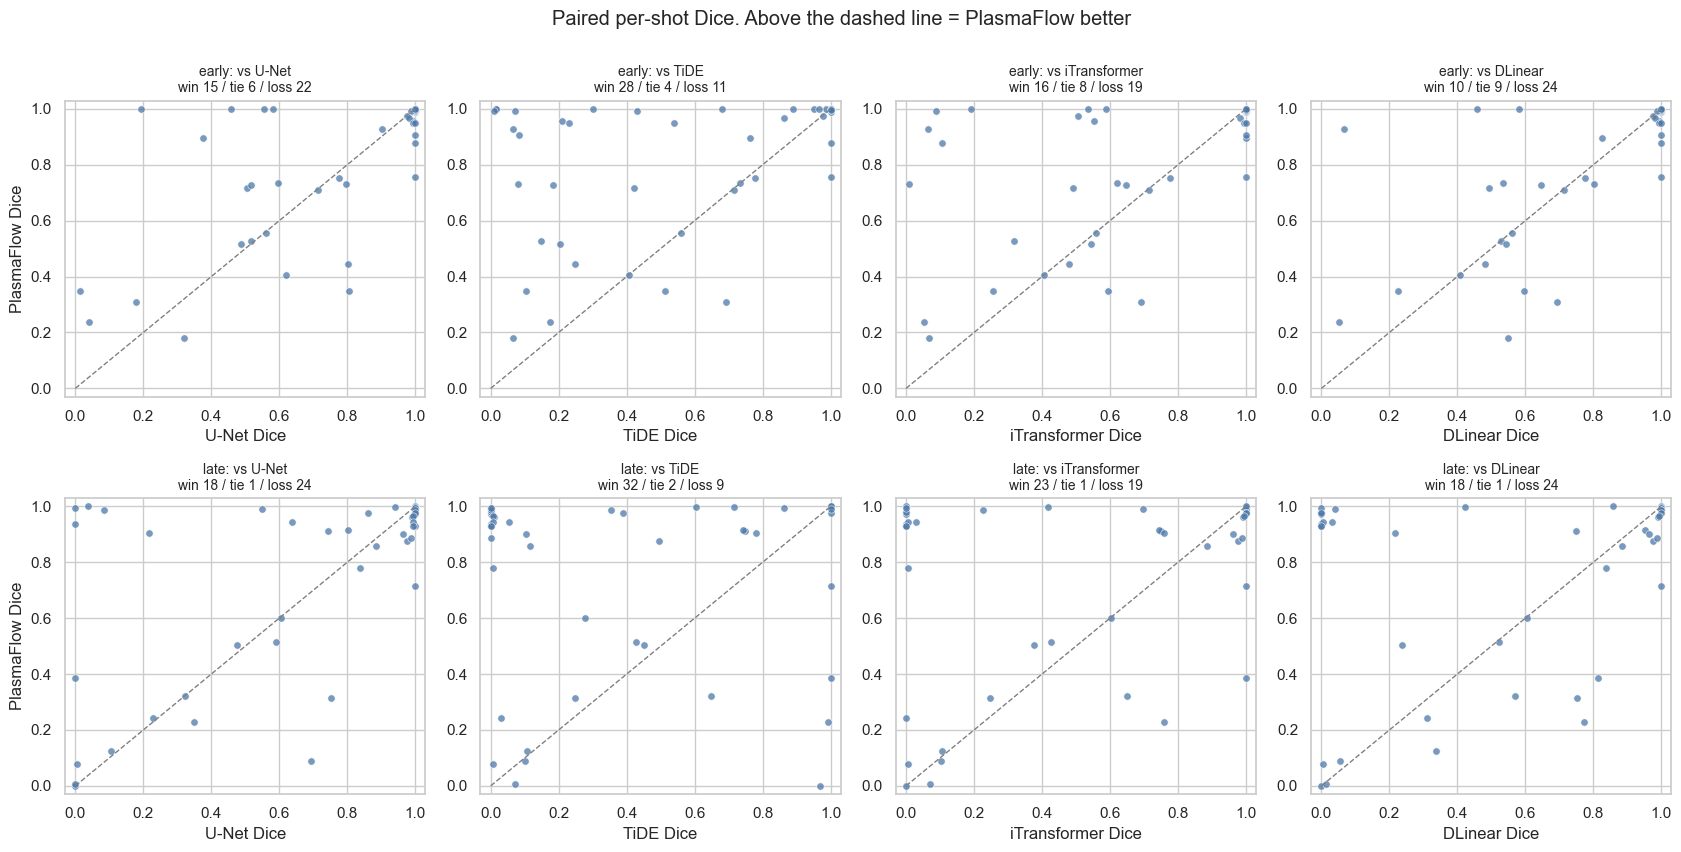

 half     baseline  n  win  tie  loss  win_frac_all  win_frac_excl_ties  mean_diff
early        U-Net 43   15    6    22         0.349               0.405      0.049
early         TiDE 43   28    4    11         0.651               0.718      0.263
early iTransformer 43   16    8    19         0.372               0.457      0.129
early      DLinear 43   10    9    24         0.233               0.294      0.021
 late        U-Net 43   18    1    24         0.419               0.429      0.093
 late         TiDE 43   32    2     9         0.744               0.780      0.356
 late iTransformer 43   23    1    19         0.535               0.548      0.229
 late      DLinear 43   18    1    24         0.419               0.429      0.203


In [5]:
def win_tie_loss(a, b, tol=TIE_TOL):
    # Counts of (a better, tied, a worse), where higher Dice is better.
    diff = a - b
    tie = np.abs(diff) <= tol
    return int((diff > tol).sum()), int(tie.sum()), int((diff < -tol).sum())

fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
rows = []
for r, half in enumerate(["early", "late"]):
    pf = per_shot[(per_shot.model == "PlasmaFlow") & (per_shot.half == half)].set_index("shot")["dice"]
    for c, base in enumerate(BASELINES):
        bl = per_shot[(per_shot.model == base) & (per_shot.half == half)].set_index("shot")["dice"]
        shots = pf.index.intersection(bl.index)
        a, b = pf.loc[shots].values, bl.loc[shots].values
        w, t, l = win_tie_loss(a, b)
        ax = axes[r, c]
        ax.scatter(b, a, s=28, alpha=0.75, color="#4C78A8", edgecolor="white", linewidth=0.5)
        ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
        ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
        ax.set_title(f"{half}: vs {base}\nwin {w} / tie {t} / loss {l}", fontsize=10)
        ax.set_xlabel(f"{base} Dice"); ax.set_ylabel("PlasmaFlow Dice" if c == 0 else "")
        rows.append(dict(half=half, baseline=base, n=len(shots), win=w, tie=t, loss=l,
                         win_frac_all=w / len(shots),
                         win_frac_excl_ties=w / (w + l) if (w + l) else np.nan,
                         mean_diff=float((a - b).mean())))
fig.suptitle("Paired per-shot Dice. Above the dashed line = PlasmaFlow better", y=1.0)
plt.tight_layout(); plt.show()

wtl = pd.DataFrame(rows)
print(wtl.round(3).to_string(index=False))

Two things to read off this table.

First, the **win fractions sit below 0.5** against U-Net, iTransformer and DLinear even though
PlasmaFlow's mean is higher in every case. So the higher mean is not coming from winning more often.

Second, look at the **tie** counts and at the cluster of dots in the top right corner of each panel.
Those are shots where both models score the same, essentially perfect, value. The exact-tie counts on
their own look modest, but the pile-up of dots near the top right is larger than the tie count
suggests, because many shots are near-ceiling without being exactly equal. Section 7 shows that both
the exact ties and the near-ceiling cluster are overwhelmingly the same shots, namely the ones whose
ground truth never changes mode.

## 5. Where the ground-truth mode labels come from

To test the hypothesis we need the real mode labels, not just the Dice summary. Here is the trail:

- **Produced by:** `src/metrics/evaluate_modes.py`. A pretrained FNOLSTM classifier is run over the
  PD (photodiode / H-alpha) trace and argmaxed into a label per timestep. It is applied to both the
  real and the generated signal, because true mode labels exist only for the history part of a shot,
  so the future labels are a *surrogate* in both cases.
- **Consumed for Dice by:** `src/metrics/rollout_peaks.py::record_slice_rows`, which slices the label
  arrays per rollout window and calls `dice_scores`.
- **Cached in:** `output/test_cache/<run_name>_rollout.h5`, as the datasets `surr_labels_real` and
  `surr_labels_gen` inside each `<shot>/<start_idx>/<sample_idx>` group. These span
  `history + rollout`, so they give us per-timestep labels for free, with no rerun needed.

Two practical traps in reading these caches, both of which cost me time:

1. The record attributes (`start_frac`, `n_windows`, ...) live on the **sample-level** group, not on
   the shot or start group.
2. `start_idx` is an **absolute** sample index, so the group name differs from shot to shot for the
   same `start_frac`. You must look up the group whose `start_frac` is 0.5 rather than assuming a
   fixed key name.

In [6]:
def find_start_group(shot_group, target_frac=START_FRAC, tol=1e-6):
    # The <start_idx> group whose records have start_frac == target_frac.
    # The key name varies per shot, so it has to be looked up rather than assumed.
    for key in shot_group.keys():
        any_sample = next(iter(shot_group[key].values()))
        if abs(float(any_sample.attrs["start_frac"]) - target_frac) < tol:
            return shot_group[key]
    return None

def window_slice(labels, k):
    # The label span Dice uses for rollout window k, matching record_slice_rows.
    return labels[HIST + k * STEP - SPILL: HIST + k * STEP + STEP]

# Pull every model's labels for the start_frac=0.5 rollout of every shot.
label_store = {}     # (model, shot) -> dict(real=1D array, gen=list of 1D arrays, n_windows=int)
for mname, run in MODELS.items():
    with h5py.File(CACHE / f"{run}.h5", "r") as f:
        for shot in f.keys():
            g = find_start_group(f[shot])
            if g is None:
                continue
            samples = sorted(g.keys(), key=int)
            real = np.asarray(g[samples[0]]["surr_labels_real"]).astype(int)
            gens = [np.asarray(g[s]["surr_labels_gen"]).astype(int) for s in samples]
            # the ground truth must not depend on which sample we read it from
            assert all(np.array_equal(real, np.asarray(g[s]["surr_labels_real"]).astype(int))
                       for s in samples), f"GT labels differ across samples for {mname} {shot}"
            label_store[(mname, int(shot))] = dict(
                real=real, gen=gens, n_windows=int(g[samples[0]].attrs["n_windows"]))

shots_all = sorted({s for (_, s) in label_store})
print("shots loaded:", len(shots_all))
print("n_windows per shot: min %d, max %d" % (
    min(v["n_windows"] for v in label_store.values()),
    max(v["n_windows"] for v in label_store.values())))

# The ground truth should in principle be identical across models, since it is the same real
# signal passed through the same classifier. Check rather than assume.
gt_diffs = []
for shot in shots_all:
    ref = label_store[("PlasmaFlow", shot)]["real"]
    for m in MODELS:
        other = label_store[(m, shot)]["real"]
        if len(other) != len(ref):
            gt_diffs.append((shot, m, "length", len(ref), len(other)))
        elif not np.array_equal(ref, other):
            gt_diffs.append((shot, m, "content", int((ref != other).sum()), len(ref)))

if not gt_diffs:
    print("ground-truth labels are identical across all 5 models: OK")
else:
    dd = pd.DataFrame(gt_diffs, columns=["shot", "model", "kind", "n_differing", "n_total"])
    print("NOTE: the cached ground-truth labels are not bit-identical across every model.")
    print(dd.assign(pct=(100 * dd.n_differing / dd.n_total).round(3)).to_string(index=False))
    print("\nAffected shots: %d of %d. Largest disagreement: %.3f%% of timesteps."
          % (dd.shot.nunique(), len(shots_all), (100 * dd.n_differing / dd.n_total).max()))
    print("This is a handful of timesteps per shot, almost certainly classifier nondeterminism")
    print("on the real trace rather than a different ground truth. It is far too small to affect")
    print("any conclusion below. We use PlasmaFlow's copy as the single reference ground truth.")

shots loaded: 43
n_windows per shot: min 12, max 49
NOTE: the cached ground-truth labels are not bit-identical across every model.
 shot        model    kind  n_differing  n_total   pct
63878        U-Net content           10     7680 0.130
63878 iTransformer content           10     7680 0.130
64686        U-Net content           10     8192 0.122
64686 iTransformer content           10     8192 0.122
65469        U-Net content           10     7168 0.140
65469 iTransformer content           10     7168 0.140
76304        U-Net content           20     5376 0.372
76304 iTransformer content           20     5376 0.372
77196        U-Net content           10     7424 0.135
77196 iTransformer content           10     7424 0.135

Affected shots: 5 of 43. Largest disagreement: 0.372% of timesteps.
This is a handful of timesteps per shot, almost certainly classifier nondeterminism
on the real trace rather than a different ground truth. It is far too small to affect
any conclusion below. We 

### Validating the reimplementation

Before drawing conclusions from labels we loaded ourselves, we check that recomputing Dice from those
labels reproduces the published `dice` column in the parquet. If this matches, we know we are slicing
the labels the same way the paper's pipeline did.

In [7]:
recomp = []
for (mname, shot), rec in label_store.items():
    for half, ks in HALVES.items():
        micros = []
        for gen in rec["gen"]:
            per_window = [dice_scores(window_slice(gen, k), window_slice(rec["real"], k))[0] for k in ks]
            micros.append(np.mean(per_window))
        recomp.append(dict(model=mname, shot=shot, half=half, dice_recomputed=float(np.mean(micros))))
recomp = pd.DataFrame(recomp)

chk = per_shot.merge(recomp, on=["model", "shot", "half"])
chk["abs_err"] = (chk["dice"] - chk["dice_recomputed"]).abs()
print("rows compared:", len(chk))
print("max |published - recomputed| = %.3e" % chk["abs_err"].max())
print("all agree to 1e-9:", bool((chk["abs_err"] < 1e-9).all()))

rows compared: 430
max |published - recomputed| = 3.331e-16
all agree to 1e-9: True


## 6. Does the ground truth even contain a transition?

Now the actual hypothesis. For each shot and half we compute, from the ground-truth labels only:

- **number of transitions**: how many times the real label changes value inside the half,
- **fraction of time in L, D, H**,
- **dominant-mode fraction**: the share of timesteps spent in the single most common mode. A value of
  1.0 means the shot never leaves one mode in that half, so there is nothing dynamic to predict.

The dominant-mode fraction is also the score that a **trivial constant predictor** would get: a
"model" that always emits the shot's most common mode and never transitions scores exactly this on
micro Dice. That makes it the right reference line for judging whether a reported `D` is impressive.

How many shots contain at least one ground-truth mode transition?
       n_with_transition  n_shots   frac
half                                    
early                 21       43  0.488
late                  25       43  0.581

Dominant-mode fraction of the ground truth (= score of a trivial constant predictor):
        mean    50%    min  max
half                           
early  0.867  1.000  0.407  1.0
late   0.904  0.994  0.427  1.0


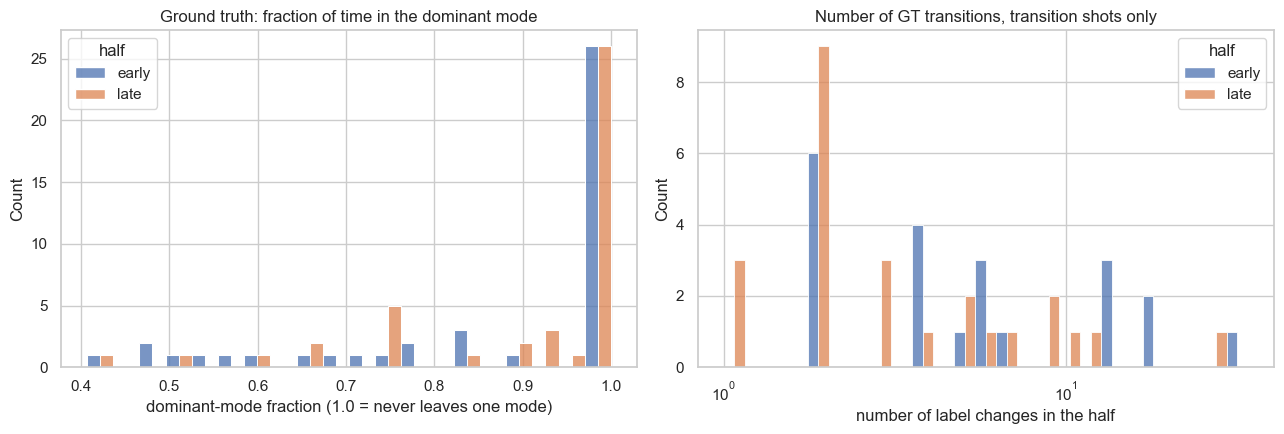

In [8]:
gt_rows = []
for shot in shots_all:
    real = label_store[("PlasmaFlow", shot)]["real"]
    for half, ks in HALVES.items():
        seg = np.concatenate([window_slice(real, k) for k in ks])
        counts = np.bincount(seg, minlength=3)
        frac = counts / counts.sum()
        dom = int(np.argmax(counts))
        n_trans = int((np.diff(seg) != 0).sum())
        gt_rows.append(dict(
            shot=shot, half=half, n_transitions_gt=n_trans,
            has_transition=n_trans > 0,
            frac_L=frac[0], frac_D=frac[1], frac_H=frac[2],
            dominant_mode=MODE_NAMES[dom], dominant_frac=float(frac[dom]),
            trivial_constant_dice=float(frac[dom])))
gt = pd.DataFrame(gt_rows)

print("How many shots contain at least one ground-truth mode transition?")
print(gt.groupby("half")["has_transition"].agg(n_with_transition="sum", n_shots="size",
                                               frac="mean").round(3))
print("\nDominant-mode fraction of the ground truth (= score of a trivial constant predictor):")
print(gt.groupby("half")["dominant_frac"].describe()[["mean", "50%", "min", "max"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=gt, x="dominant_frac", hue="half", bins=20, multiple="dodge", ax=axes[0])
axes[0].set_title("Ground truth: fraction of time in the dominant mode")
axes[0].set_xlabel("dominant-mode fraction (1.0 = never leaves one mode)")
sns.histplot(data=gt[gt.n_transitions_gt > 0], x="n_transitions_gt", hue="half",
             bins=25, multiple="dodge", ax=axes[1], log_scale=(True, False))
axes[1].set_title("Number of GT transitions, transition shots only")
axes[1].set_xlabel("number of label changes in the half")
plt.tight_layout(); plt.show()

Now the key comparison: how does each model's reported `D` stack up against that trivial
constant-mode predictor? If a model cannot beat "always guess the most common mode", then its `D`
is not evidence that it reproduces mode dynamics.

In [9]:
ref = gt.groupby("half")["trivial_constant_dice"].mean()
summary = per_shot.pivot_table(index="model", columns="half", values="dice").loc[list(MODELS)]
summary_macro = per_shot.pivot_table(index="model", columns="half", values="dice_macro").loc[list(MODELS)]
out = pd.DataFrame({
    "D early": summary["early"], "D late": summary["late"],
    "macro early": summary_macro["early"], "macro late": summary_macro["late"]})
out.loc["** trivial constant-mode predictor **"] = [ref["early"], ref["late"], np.nan, np.nan]
print(out.round(3).to_string())
print("\nTrivial constant-mode reference: D = %.3f (early), %.3f (late)" % (ref["early"], ref["late"]))
print("Models that BEAT the trivial reference on D:")
for half in ["early", "late"]:
    better = [m for m in MODELS if summary.loc[m, half] > ref[half]]
    print(f"  {half}: {better if better else 'none'}")

                                       D early  D late  macro early  macro late
model                                                                          
PlasmaFlow                               0.799   0.735        0.722       0.666
U-Net                                    0.750   0.643        0.685       0.570
TiDE                                     0.537   0.380        0.479       0.356
iTransformer                             0.671   0.507        0.625       0.472
DLinear                                  0.778   0.533        0.727       0.491
** trivial constant-mode predictor **    0.867   0.904          NaN         NaN

Trivial constant-mode reference: D = 0.867 (early), 0.904 (late)
Models that BEAT the trivial reference on D:
  early: none
  late: none


## 7. The paired test, split by whether a transition exists

This is the direct test of the hypothesis. We repeat the PlasmaFlow-versus-baseline paired comparison
twice: once on the shots whose ground truth stays in a single mode, and once on the shots that
actually contain a transition. If the hypothesis is right, the no-transition group should show
near-ceiling scores, tiny differences and no significance, while the transition group is where any
real signal must live.

**On ties and the Wilcoxon test.** The Wilcoxon signed-rank test ranks the paired differences. Shots
where the two models score identically produce a difference of exactly zero, and the test has to
decide what to do with them. `zero_method="wilcox"` (the scipy default) **discards** them, which
shrinks the effective sample size and can inflate significance. `zero_method="zsplit"` **keeps** them
and splits them evenly between positive and negative ranks, which is the conservative choice when
there are many ties. We report both, plus a plain sign test on the non-tied shots, so you can see
that the conclusion does not hinge on this choice.

In [10]:
def paired_report(a, b, label):
    a, b = np.asarray(a, float), np.asarray(b, float)
    diff = a - b
    n = len(diff)
    w, t, l = win_tie_loss(a, b)
    row = dict(group=label, n=n, win=w, tie=t, loss=l,
               mean_diff=diff.mean(),
               se_diff=diff.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan,
               win_frac_all=w / n if n else np.nan,
               win_frac_excl_ties=w / (w + l) if (w + l) else np.nan)
    for zm in ("wilcox", "zsplit"):
        try:
            row[f"p_{zm}"] = wilcoxon(a, b, zero_method=zm).pvalue
        except ValueError:
            row[f"p_{zm}"] = np.nan
    row["p_sign"] = binomtest(w, w + l, 0.5).pvalue if (w + l) > 0 else np.nan
    return row

merged = per_shot.merge(gt, on=["shot", "half"])
split_rows = []
for half in ["early", "late"]:
    for base in BASELINES:
        for grp_name, mask in [("no transition", False), ("has transition", True)]:
            sel = merged[(merged.half == half) & (merged.has_transition == mask)]
            pf = sel[sel.model == "PlasmaFlow"].set_index("shot")["dice"]
            bl = sel[sel.model == base].set_index("shot")["dice"]
            shots = pf.index.intersection(bl.index)
            if len(shots) < 2:
                continue
            r = paired_report(pf.loc[shots].values, bl.loc[shots].values, grp_name)
            r.update(half=half, baseline=base)
            split_rows.append(r)
        sel = merged[merged.half == half]
        pf = sel[sel.model == "PlasmaFlow"].set_index("shot")["dice"]
        bl = sel[sel.model == base].set_index("shot")["dice"]
        shots = pf.index.intersection(bl.index)
        r = paired_report(pf.loc[shots].values, bl.loc[shots].values, "ALL shots")
        r.update(half=half, baseline=base)
        split_rows.append(r)

split = pd.DataFrame(split_rows)[
    ["half", "baseline", "group", "n", "win", "tie", "loss", "win_frac_all",
     "win_frac_excl_ties", "mean_diff", "se_diff", "p_wilcox", "p_zsplit", "p_sign"]]
for half in ["early", "late"]:
    print(f"\n===== {half.upper()} HALF =====")
    print(split[split.half == half].drop(columns="half").round(4).to_string(index=False))


===== EARLY HALF =====


    baseline          group  n  win  tie  loss  win_frac_all  win_frac_excl_ties  mean_diff  se_diff  p_wilcox  p_zsplit  p_sign
       U-Net  no transition 22    6    6    10        0.2727              0.3750     0.1000   0.0560    0.7564    0.8452  0.4545
       U-Net has transition 21    9    0    12        0.4286              0.4286    -0.0036   0.0405    0.9187    0.9187  0.6636
       U-Net      ALL shots 43   15    6    22        0.3488              0.4054     0.0494   0.0353    0.7457    0.9952  0.3240
        TiDE  no transition 22   14    3     5        0.6364              0.7368     0.3162   0.0903    0.0043    0.0061  0.0636
        TiDE has transition 21   14    1     6        0.6667              0.7000     0.2068   0.0676    0.0124    0.0136  0.1153
        TiDE      ALL shots 43   28    4    11        0.6512              0.7179     0.2628   0.0567    0.0001    0.0002  0.0095
iTransformer  no transition 22    5    7    10        0.2273              0.3333     0.1293   0.0

In [11]:
# Where do the exact ties actually sit? This is the sharpest test of the hypothesis.
tie_rows = []
for half in ["early", "late"]:
    for base in BASELINES:
        sel = merged[merged.half == half]
        pf = sel[sel.model == "PlasmaFlow"].set_index("shot")
        bl = sel[sel.model == base].set_index("shot")["dice"]
        shots = pf.index.intersection(bl.index)
        tied = np.abs(pf.loc[shots, "dice"].values - bl.loc[shots].values) <= TIE_TOL
        has_tr = pf.loc[shots, "has_transition"].values
        tie_rows.append(dict(half=half, baseline=base, n_ties=int(tied.sum()),
                             ties_in_no_transition=int((tied & ~has_tr).sum()),
                             ties_in_has_transition=int((tied & has_tr).sum())))
ties = pd.DataFrame(tie_rows)
print("Where the exact ties sit (no-transition shots vs transition shots):")
print(ties.to_string(index=False))
print("\nTotals: %d ties in no-transition shots, %d in transition shots."
      % (ties.ties_in_no_transition.sum(), ties.ties_in_has_transition.sum()))
print("For reference the two groups are of similar size (22 vs 21 early, 18 vs 25 late),")
print("so an even split would be expected if transitions were irrelevant to tying.")

Where the exact ties sit (no-transition shots vs transition shots):
 half     baseline  n_ties  ties_in_no_transition  ties_in_has_transition
early        U-Net       6                      6                       0
early         TiDE       4                      3                       1
early iTransformer       8                      7                       1
early      DLinear       9                      8                       1
 late        U-Net       1                      1                       0
 late         TiDE       2                      2                       0
 late iTransformer       1                      1                       0
 late      DLinear       1                      1                       0

Totals: 29 ties in no-transition shots, 3 in transition shots.
For reference the two groups are of similar size (22 vs 21 early, 18 vs 25 late),
so an even split would be expected if transitions were irrelevant to tying.


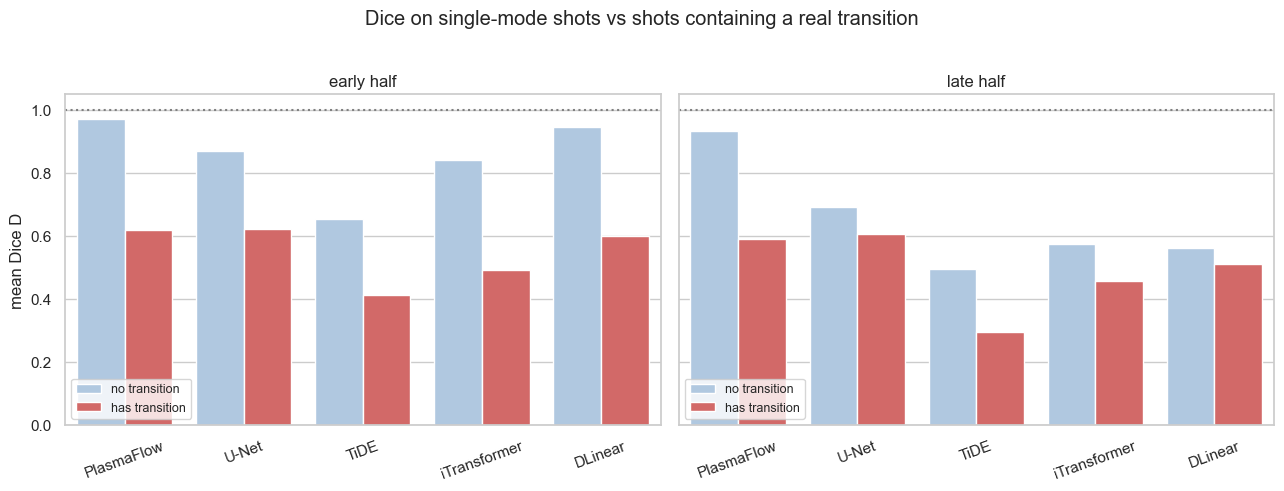

half                    early                         late              
has_transition has transition no transition has transition no transition
model                                                                   
PlasmaFlow              0.620         0.971          0.592         0.935
U-Net                   0.624         0.871          0.606         0.693
TiDE                    0.413         0.654          0.296         0.496
iTransformer            0.492         0.841          0.458         0.575
DLinear                 0.600         0.948          0.511         0.563


In [12]:
# Mean Dice by group: the ceiling effect made visual.
grp = (merged.groupby(["model", "half", "has_transition"])["dice"].mean().reset_index()
       .replace({"has_transition": {False: "no transition", True: "has transition"}}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, half in zip(axes, ["early", "late"]):
    sns.barplot(data=grp[grp.half == half], x="model", y="dice", hue="has_transition",
                order=list(MODELS), ax=ax, palette={"no transition": "#A8C8E8", "has transition": "#E45756"})
    ax.axhline(1.0, ls=":", color="grey")
    ax.set_title(f"{half} half"); ax.set_xlabel(""); ax.set_ylabel("mean Dice D")
    ax.tick_params(axis="x", rotation=20); ax.set_ylim(0, 1.05)
    ax.legend(title="", loc="lower left", fontsize=9)
fig.suptitle("Dice on single-mode shots vs shots containing a real transition", y=1.02)
plt.tight_layout(); plt.show()

print(grp.pivot_table(index="model", columns=["half", "has_transition"], values="dice")
      .loc[list(MODELS)].round(3).to_string())

## 8. Does any model actually produce a transition?

A complementary question that `D` never asks: does the model's output even *contain* a mode change?
A model that emits a flat, mean-collapsed signal gets classified as one constant mode and so can
never reproduce a transition, however good its `D` looks. For PlasmaFlow we report the fraction of
its 30 samples that contain a transition; the baselines have a single deterministic output.

In [13]:
trans_rows = []
for (mname, shot), rec in label_store.items():
    for half, ks in HALVES.items():
        gen_has = []
        for gen in rec["gen"]:
            seg = np.concatenate([window_slice(gen, k) for k in ks])
            gen_has.append((np.diff(seg) != 0).sum() > 0)
        trans_rows.append(dict(model=mname, shot=shot, half=half,
                               frac_samples_with_transition=float(np.mean(gen_has)),
                               any_sample_has_transition=bool(np.any(gen_has))))
tr = pd.DataFrame(trans_rows).merge(gt[["shot", "half", "has_transition"]], on=["shot", "half"])

print("Fraction of shots where the model's output contains at least one mode transition:")
print(tr.pivot_table(index="model", columns="half", values="any_sample_has_transition")
      .loc[list(MODELS)].round(3).to_string())
print("\nRestricted to shots where the GROUND TRUTH has a transition:")
print(tr[tr.has_transition].pivot_table(index="model", columns="half",
                                        values="any_sample_has_transition")
      .loc[list(MODELS)].round(3).to_string())
print("\nFor reference, GT transition rate per half:")
print(gt.groupby("half")["has_transition"].mean().round(3).to_string())

Fraction of shots where the model's output contains at least one mode transition:
half          early   late
model                     
PlasmaFlow    0.767  0.953
U-Net         0.488  0.302
TiDE          0.581  0.279
iTransformer  0.279  0.163
DLinear       0.233  0.302

Restricted to shots where the GROUND TRUTH has a transition:
half          early  late
model                    
PlasmaFlow    0.952  1.00
U-Net         0.714  0.32
TiDE          0.524  0.24
iTransformer  0.333  0.16
DLinear       0.286  0.36

For reference, GT transition rate per half:
half
early    0.488
late     0.581


## 9. Full-shot Dice, and transition timing error

Two extras that the cached labels support without any rerun.

**Full-shot Dice.** The paper table stops at window 11, but the caches store labels for the whole
rollout, which runs to between 12 and 49 windows depending on shot length. Averaging Dice over *all*
windows tests whether the 12-window cut is hiding anything.

**Transition timing error.** This is the measure `D` cannot provide. We define the *H onset* as the
first timestep in the generated region where the label becomes H, for shots whose ground truth starts
in L and later reaches H. The error is the signed gap between the real onset and the generated onset,
in milliseconds at 10 kHz (1 sample = 0.1 ms). A model whose output never reaches H has no onset at
all, which is itself the most informative possible result and is reported as a miss rate.

In [14]:
# ---- full-shot Dice over every available window ----
full_rows = []
for (mname, shot), rec in label_store.items():
    ks = range(rec["n_windows"])
    micros, macros = [], []
    for gen in rec["gen"]:
        pw = [dice_scores(window_slice(gen, k), window_slice(rec["real"], k)) for k in ks]
        micros.append(np.mean([x[0] for x in pw]))
        macros.append(np.mean([x[1] for x in pw]))
    full_rows.append(dict(model=mname, shot=shot, n_windows=rec["n_windows"],
                          dice_full=float(np.mean(micros)), dice_macro_full=float(np.mean(macros))))
full = pd.DataFrame(full_rows)

cmp_full = full.groupby("model")[["dice_full", "dice_macro_full"]].mean().loc[list(MODELS)]
cmp_full["D early (12-window table)"] = summary["early"]
cmp_full["D late (12-window table)"] = summary["late"]
print("Dice over ALL rollout windows vs the 12-window table values:")
print(cmp_full.round(3).to_string())

print("\nPaired test on full-shot Dice, PlasmaFlow vs each baseline:")
pf_full = full[full.model == "PlasmaFlow"].set_index("shot")["dice_full"]
fr = []
for base in BASELINES:
    bl = full[full.model == base].set_index("shot")["dice_full"]
    shots = pf_full.index.intersection(bl.index)
    r = paired_report(pf_full.loc[shots].values, bl.loc[shots].values, f"full shot vs {base}")
    fr.append(r)
print(pd.DataFrame(fr).round(4).to_string(index=False))

Dice over ALL rollout windows vs the 12-window table values:
              dice_full  dice_macro_full  D early (12-window table)  D late (12-window table)
model                                                                                        
PlasmaFlow        0.721            0.649                      0.799                     0.735
U-Net             0.632            0.563                      0.750                     0.643
TiDE              0.470            0.433                      0.537                     0.380
iTransformer      0.536            0.497                      0.671                     0.507
DLinear           0.572            0.528                      0.778                     0.533

Paired test on full-shot Dice, PlasmaFlow vs each baseline:
                    group  n  win  tie  loss  mean_diff  se_diff  win_frac_all  win_frac_excl_ties  p_wilcox  p_zsplit  p_sign
       full shot vs U-Net 43   26    0    17     0.0892   0.0360        0.6047              0

In [15]:
# ---- transition timing: first L -> H onset in the generated region ----
def first_h_onset(labels_full, n_windows):
    # Index within the generated region of the first H label, or None if H never occurs.
    gen_region = labels_full[HIST: HIST + n_windows * STEP]
    hits = np.flatnonzero(gen_region == 2)
    return int(hits[0]) if hits.size else None

MS_PER_SAMPLE = 1000.0 / SAMPLE_RATE
timing = []
for shot in shots_all:
    rec_pf = label_store[("PlasmaFlow", shot)]
    nw = rec_pf["n_windows"]
    real = rec_pf["real"]
    gen_region_real = real[HIST: HIST + nw * STEP]
    # only meaningful where the GT starts in L and later reaches H
    if gen_region_real[0] != 0:
        continue
    t_real = first_h_onset(real, nw)
    if t_real is None:
        continue
    for mname in MODELS:
        rec = label_store[(mname, shot)]
        errs = []
        misses = 0
        for gen in rec["gen"]:
            t_gen = first_h_onset(gen, nw)
            if t_gen is None:
                misses += 1
            else:
                errs.append((t_gen - t_real) * MS_PER_SAMPLE)
        timing.append(dict(model=mname, shot=shot, n_samples=len(rec["gen"]),
                           miss_frac=misses / len(rec["gen"]),
                           signed_err_ms=float(np.mean(errs)) if errs else np.nan,
                           abs_err_ms=float(np.mean(np.abs(errs))) if errs else np.nan))
tm = pd.DataFrame(timing)

print("Shots where the ground truth has a clean L -> H onset in the rollout:", tm.shot.nunique())
print("\nFirst-H-onset timing, averaged over shots (NaN abs_err = model never reached H anywhere):")
print(tm.groupby("model").agg(
    shots=("shot", "nunique"),
    frac_outputs_never_reaching_H=("miss_frac", "mean"),
    median_abs_err_ms=("abs_err_ms", "median"),
    mean_abs_err_ms=("abs_err_ms", "mean"),
    mean_signed_err_ms=("signed_err_ms", "mean"),
).loc[list(MODELS)].round(2).to_string())
print("\nNote: a high 'frac_outputs_never_reaching_H' means the model simply never produces an H phase,")
print("so its timing error is undefined rather than good. Read the two columns together.")

Shots where the ground truth has a clean L -> H onset in the rollout: 20

First-H-onset timing, averaged over shots (NaN abs_err = model never reached H anywhere):
              shots  frac_outputs_never_reaching_H  median_abs_err_ms  mean_abs_err_ms  mean_signed_err_ms
model                                                                                                     
PlasmaFlow       20                           0.08              41.23            85.06              -18.77
U-Net            20                           0.00              75.50           117.50              -88.20
TiDE             20                           0.65              83.00           177.71              -32.86
iTransformer     20                           0.55             268.00           235.89                0.11
DLinear          20                           0.20             176.50           184.19               25.69

Note: a high 'frac_outputs_never_reaching_H' means the model simply never produces an 

## 10. What this looks like on individual shots

Finally, the picture behind the statistics. Each strip is a label sequence over the first 12 windows:
ground truth on top, then PlasmaFlow (one representative sample), then one baseline. Colour is the
mode: blue L, orange D, red H. The vertical lines mark window boundaries.

Two shots whose ground truth never changes mode, and two that do.

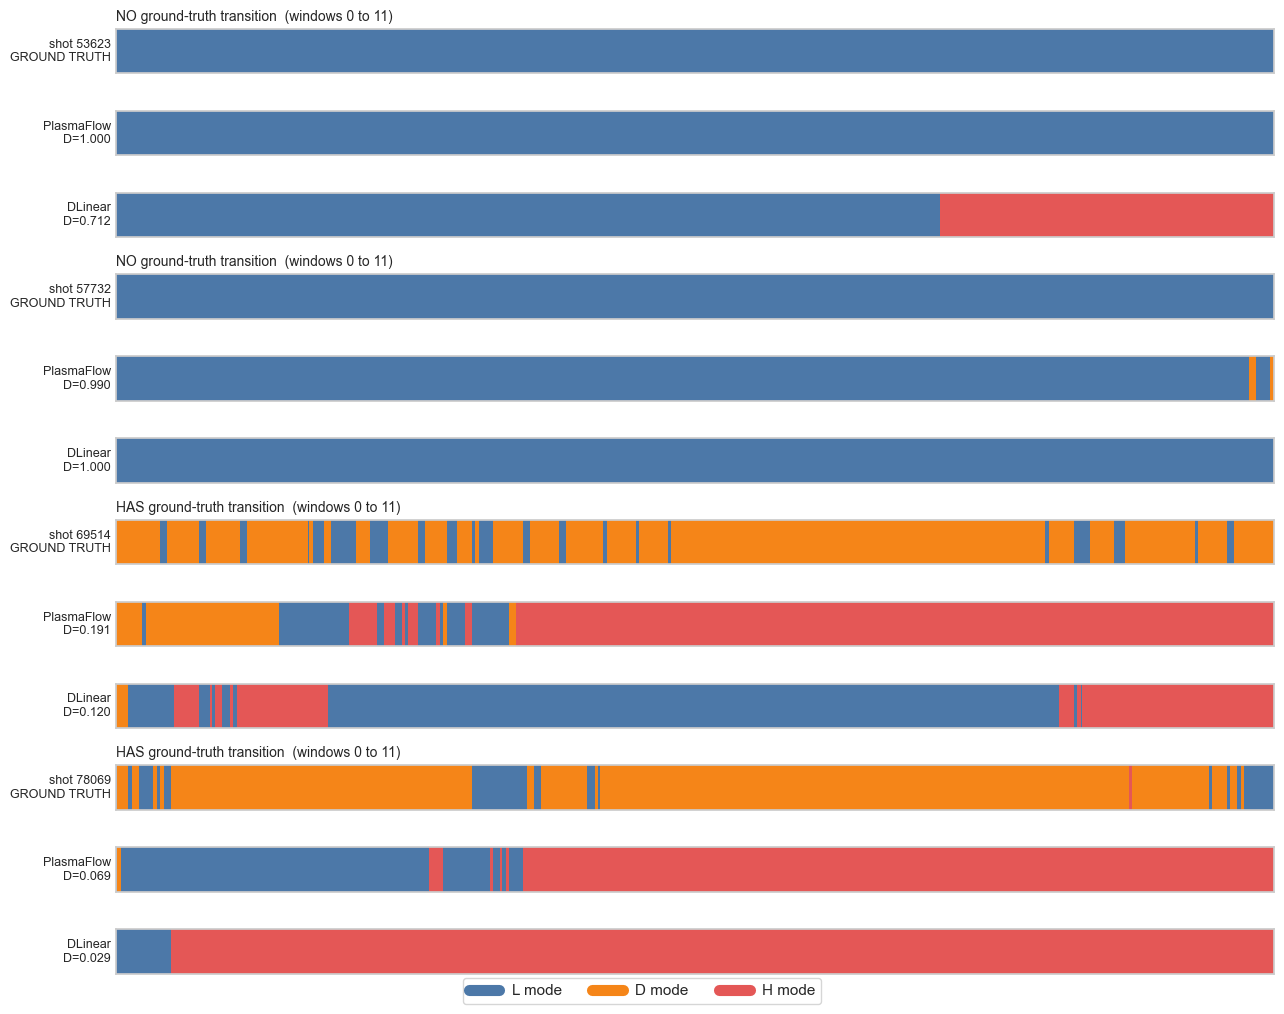

In [16]:
def label_strip(ax, seg, title):
    ax.imshow(seg.reshape(1, -1), aspect="auto", interpolation="nearest",
              cmap=plt.matplotlib.colors.ListedColormap([MODE_COLORS[0], MODE_COLORS[1], MODE_COLORS[2]]),
              vmin=0, vmax=2)
    ax.set_yticks([]); ax.set_xticks([])
    ax.set_ylabel(title, rotation=0, ha="right", va="center", fontsize=9)

HALF_KS = list(HALVES["early"]) + list(HALVES["late"])
show_base = "DLinear"
sel_half = "early"
g = gt[gt.half == sel_half]
no_tr = g[~g.has_transition].sort_values("dominant_frac", ascending=False).shot.tolist()[:2]
has_tr = g[g.has_transition].sort_values("n_transitions_gt", ascending=False).shot.tolist()[:2]

fig, axes = plt.subplots(12, 1, figsize=(13, 10))
i = 0
for group_label, shot_list in [("NO ground-truth transition", no_tr), ("HAS ground-truth transition", has_tr)]:
    for shot in shot_list:
        real = label_store[("PlasmaFlow", shot)]["real"]
        seg_real = np.concatenate([window_slice(real, k) for k in HALF_KS])
        seg_pf = np.concatenate([window_slice(label_store[("PlasmaFlow", shot)]["gen"][0], k) for k in HALF_KS])
        seg_bl = np.concatenate([window_slice(label_store[(show_base, shot)]["gen"][0], k) for k in HALF_KS])
        d_pf = dice_scores(seg_pf, seg_real)[0]
        d_bl = dice_scores(seg_bl, seg_real)[0]
        label_strip(axes[i], seg_real, f"shot {shot}\nGROUND TRUTH"); i += 1
        label_strip(axes[i], seg_pf, f"PlasmaFlow\nD={d_pf:.3f}"); i += 1
        label_strip(axes[i], seg_bl, f"{show_base}\nD={d_bl:.3f}"); i += 1
        axes[i - 3].set_title(f"{group_label}  (windows 0 to 11)", fontsize=10, loc="left")
handles = [plt.Line2D([0], [0], color=MODE_COLORS[c], lw=8, label=f"{MODE_NAMES[c]} mode") for c in (0, 1, 2)]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(); plt.show()

## 11. Summary

### Is the hypothesis confirmed?

**Yes, and the data pin down the mechanism precisely.**

1. **About half the evaluated halves contain no mode transition at all**: 21 of 43 shots have a
   ground-truth transition in the early half, 25 of 43 in the late half. The *median* shot has a
   dominant-mode fraction of 1.000 (early) and 0.994 (late), meaning the typical shot simply never
   leaves one confinement mode over the window span.
2. **On those no-transition shots every model scores near the ceiling.** Early half: PlasmaFlow
   0.971, DLinear 0.948, U-Net 0.871, iTransformer 0.841. There is almost no room for a model to
   distinguish itself.
3. **The ties live almost entirely in the no-transition group**, which is exactly what the hypothesis
   predicted. Against DLinear in the early half, 8 of the 9 exact ties are no-transition shots, with
   only 1 tie among the 21 transition shots. Against iTransformer early it is 7 ties versus 1.
4. **No model beats a trivial constant-mode predictor** on the reported 12-window `D`. That trivial
   reference scores 0.867 (early) and 0.904 (late), above every model in the table, purely because
   the ground-truth mode distribution is so skewed.
5. **`D` fails to separate the models even on the hard shots.** Restricted to transition-containing
   shots, PlasmaFlow versus U-Net is a mean difference of -0.004 (early) and -0.014 (late), and
   versus DLinear +0.020 and +0.081, none significant. Only TiDE is beaten significantly. So the
   easy shots are not merely diluting a real signal; on the 12-window span the signal is not there.

### Two findings that go beyond the original hypothesis

**The 12-window cut was hiding a genuine PlasmaFlow advantage.** Averaging Dice over *all* rollout
windows (12 to 49 per shot, section 9) flips the result: PlasmaFlow is then significantly ahead of
every baseline, with Wilcoxon p = 0.028 (U-Net), 0.0002 (TiDE), 0.0002 (iTransformer), 0.006
(DLinear). The reason is that the baselines degrade faster as the rollout gets longer, and the first
12 windows are too short to expose it. One honest caveat: against U-Net and DLinear the win counts
are only 26 to 17, and the sign test on those is not significant (p = 0.22), so the full-rollout
advantage is carried by the *size* of PlasmaFlow's wins rather than their frequency. Report the win
count alongside the p-value if this result is used.

**The transition-aware measures separate the models cleanly, and `D` does not.** On shots whose
ground truth transitions, PlasmaFlow produces a mode transition in 95 percent (early) and 100 percent
(late) of cases, against 16 to 71 percent for the baselines. On first L to H onset timing, PlasmaFlow
has both the lowest median absolute error (41 ms, versus 76 for U-Net, 83 TiDE, 177 DLinear, 268
iTransformer) and the second-lowest rate of simply never producing an H phase (8 percent of outputs,
versus 0 for U-Net but 20 to 65 percent for the other three). These are the numbers that actually
demonstrate mode-dynamics fidelity.

### Which Dice-based claim the paper can defend

- **Not defensible:** that PlasmaFlow has the best mode agreement in the depth table. The mean is
  highest, but it is not statistically distinguishable from U-Net, iTransformer or DLinear, the win
  fractions are below 0.5, and no model beats a constant-mode predictor.
- **Defensible:** that PlasmaFlow leads on mode agreement over the **full rollout** (with the win
  count reported), that it is the only model reliably producing mode transitions, and that it has the
  lowest mode-onset timing error.

### Suggested wording

For the Results section, replace a blanket "captures the mode dynamics better than any baseline" with
something scoped to what the numbers actually show:

> Over the full rollout, PlasmaFlow attains the highest mode agreement of all models (Wilcoxon
> p < 0.03 against each baseline). Within the first twelve windows reported in
> \autoref{tab:rollout_results_depth} the differences are not significant against U-Net,
> iTransformer or DLinear. We attribute this to the limited sensitivity of a per-timestep agreement
> rate on this test set: about half of the evaluated windows contain no ground-truth mode transition,
> and the mode distribution is skewed enough that a constant-mode predictor already attains
> \(\mathcal{D} \approx 0.89\). The mode behaviour is better separated by transition-level measures.
> PlasmaFlow produces a mode transition in 95 to 100 percent of the shots whose ground truth
> transitions, against 16 to 71 percent for the baselines, and attains the lowest median L to H onset
> timing error (41 ms, against 76 to 268 ms).

For the table, add the constant-mode reference as an explicit row or a footnote, so a reader can see
how much headroom `D` really has, and state in the caption that `D` is a per-timestep agreement rate
rather than a transition-level score.

For the Discussion, one sentence:

> The per-timestep mode-agreement score is only weakly diagnostic over short rollouts, because most
> evaluation windows remain inside a single confinement mode and a model that rarely transitions is
> therefore barely penalised; transition-level measures and the peak-based metrics are the more
> sensitive probes of whether a model reproduces mode-change and ELM timing.

A note on the macro-averaged Dice, which is already cached in `rollout_slice_metrics.parquet` as
`dice_macro` and so needs no recomputation: it weights the rare D and H modes equally with L, which
makes it more sensitive in principle, but it does **not** rescue the claim. PlasmaFlow leads on it in
the late half (0.666 against 0.570 for the next best) but is narrowly second in the early half
(0.722 against DLinear's 0.727). It is a better-motivated metric than micro `D`, not a more
favourable one, and it should not be swapped in selectively.

**What would need a rerun, and the cheapest route.** Everything above came from cached files. If a
properly transition-weighted mode metric is wanted for the paper, the cheapest route is to add a
column inside `src/metrics/rollout_peaks.py::record_slice_rows`, which already holds the full
`surr_labels_gen` and `surr_labels_real` arrays per record, and then re-run only the metric
aggregation over the existing `output/test_cache/*_rollout.h5` caches. That recomputes metrics from
stored labels and does **not** require regenerating rollouts or re-running the classifier. No such
rerun was performed here.